# TF-IDF + SVM: klasifikasi komentar promosi judi online

Notebook ini berisi pekerjaan SVM untuk UTS Machine Learning. Kita memakai data dan pembagian dari pipeline Athar, lalu melatih serta mengevaluasi dua skenario SVM.

**Alur:** komentar bersih → TF-IDF → LinearSVC → prediksi → evaluasi.

Jalankan dari atas ke bawah. TF-IDF mengubah teks menjadi angka; SVM mempelajari batas pemisahnya. Label kerja: `0=nonjudi`, `1=promosi judi`. Dokumentasi label sumber belum terkonfirmasi.

## Hasil yang disertakan

Pada 1.787 komentar test asli: SVM dengan data asli mendapat accuracy **98,77%** dan F1 positif **98,09%**; dengan tambahan sintetis, accuracy **98,71%** dan F1 positif **98,00%**. Skenario asli saja dipilih melalui validation sebelum test.

Semua sel kode sudah dijalankan melalui IPython. Kernel Jupyter belum diverifikasi; lihat [catatan lingkungan](docs/LINGKUNGAN.md). Setelah menjalankan ulang, gunakan run ID dan hasil pada output sel terakhir.


## 1. Apa yang ingin diuji?

Bagaimana hasil TF-IDF + SVM pada data asli? Apakah menambahkan 1.066 komentar sintetis saat training membantu?

Kita menguji dua skenario SVM. Perbandingan dengan metode teman dikerjakan terpisah oleh penulis paper.

Hasil mengukur kecocokan dengan label pada split ini. Split belum menguji video atau kampanye baru, dan anotasi sumber belum diaudit sepenuhnya.


## 2. Siapkan library dan parameter

Konfigurasi ada di `config/experiment_config.json`. Kita mencoba dua jenis TF-IDF, tiga nilai C, dan dua skenario: total **12 kandidat**. Setiap kandidat mendapat pipeline baru agar vocabulary dan IDF hanya belajar dari training.

Versi library dan folder hasil dicatat otomatis.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import importlib.metadata
import json
import os
import platform
import uuid
import warnings

ROOT = Path.cwd().resolve()
if not (ROOT / 'config/experiment_config.json').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'config/experiment_config.json').is_file():
    raise FileNotFoundError('Buka notebook dari root svm-classifier.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from data_contract import load_shared_data, verify_input_hashes
from preprocessing import clean_comment
from experiment_io import require, write_json, write_csv, utc_now, sha256_file, text_sha256, code_fingerprints, git_identity, write_artifact_manifest

CONFIG = json.loads((ROOT / 'config/experiment_config.json').read_text(encoding='utf-8'))
CONFIG_SHA = sha256_file(ROOT / 'config/experiment_config.json')
CODE_HASHES = code_fingerprints(ROOT)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
RUN_DIR = ROOT / 'outputs/runs' / RUN_ID
(RUN_DIR / 'models').mkdir(parents=True, exist_ok=False)
(RUN_DIR / 'figures').mkdir()
STARTED_AT = utc_now()
EXECUTION_MODE = os.environ.get('SVM_EXECUTION_MODE', 'jupyter_kernel' if type(get_ipython()).__name__ == 'ZMQInteractiveShell' else 'sequential_ipython')
VERSIONS = {name: importlib.metadata.version(name) for name in ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib','ipython']}
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
COLORS = {'original_only':'#285E8E','with_synthetic':'#B77A18'}
print('Run:', RUN_ID)
print('Mode:', EXECUTION_MODE)
display(pd.Series(VERSIONS, name='versi').to_frame())

Run: 20261021T144408Z_faf70e90
Mode: sequential_ipython


,versi
numpy,1.26.4
pandas,3.0.3
scipy,1.17.1
scikit-learn,1.4.2
matplotlib,3.10.9
joblib,1.5.3
ipython,9.1.0


### Contoh representasi tanpa melatih model

Contoh berikut hanya memperlihatkan cara analyzer memotong teks buatan. Tidak ada fitting vocabulary/IDF atau perhitungan skor pada contoh ini. Karakter 3–5 gram tetap dibatasi per kata (`char_wb`), sedangkan word 1–2 gram memakai kata dan pasangan kata.

In [2]:
example = clean_comment('review mobil bagus')
word_analyzer = TfidfVectorizer(analyzer='word', ngram_range=(1,2)).build_analyzer()
char_analyzer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5)).build_analyzer()
print('Teks contoh:', example)
print('Word n-gram:', word_analyzer(example))
print('12 contoh character n-gram:', char_analyzer(example)[:12])

Teks contoh: review mobil bagus
Word n-gram: ['review', 'mobil', 'bagus', 'review mobil', 'mobil bagus']
12 contoh character n-gram: [' re', 'rev', 'evi', 'vie', 'iew', 'ew ', ' rev', 'revi', 'evie', 'view', 'iew ', ' revi']


## 3. Baca data Athar

Fungsi pembaca memeriksa hash input dan mencocokkan `source_row` dengan manifest pembagian data. Kita memakai ekspor Athar apa adanya, tanpa membuat split baru.

**Train** untuk melatih, **validation** untuk memilih parameter, **test** untuk evaluasi akhir. Sintetis hanya masuk training. Hanya `komentar_processed` yang menjadi fitur; ID dan metadata tidak ikut dipelajari.


In [3]:
shared = load_shared_data(ROOT)
parts = shared['parts']
synthetic = shared['synthetic']
INPUT_HASHES = shared['hashes']
train, validation, test = parts['train'], parts['validation'], parts['test']
split_table = pd.DataFrame({name: frame['label'].value_counts() for name,frame in parts.items()}).T
split_table.columns = ['label_0', 'label_1']
split_table['total'] = split_table.sum(axis=1)
display(split_table)
print('Synthetic:', len(synthetic), '| Original:', len(shared['original']))
print('SHA-256 manifest:', INPUT_HASHES['original_split_manifest.csv'])
model_columns = ['komentar_processed','label']
training_sets = {
    'original_only': train[model_columns].copy(),
    'with_synthetic': pd.concat([train[model_columns], synthetic[model_columns]], ignore_index=True),
}
display(pd.DataFrame([{'scenario':arm,'fit_rows':len(frame),'validation_rows':len(validation)} for arm,frame in training_sets.items()]))

Synthetic: 1066 | Original: 8934
SHA-256 manifest: 1512e44e643cfbf666895fadcba550fd17111a1caef9584825adcbd83a0b0781


,label_0,label_1,total
train,3610,1750,5360
validation,1203,584,1787
test,1203,584,1787


,scenario,fit_rows,validation_rows
0,original_only,5360,1787
1,with_synthetic,6426,1787


## 4. Pipeline dan definisi metrik

Pipeline berisi TF-IDF lalu LinearSVC. `fit` mempelajari kedua tahap pada bagian fitting saja. `predict` pada validation/test memakai representasi yang sudah dipelajari.

Kelas positif adalah `1`. Precision = TP/(TP+FP), recall = TP/(TP+FN), dan F1 positif = 2TP/(2TP+FP+FN). Macro-F1 adalah rata-rata F1 kedua kelas, sehingga tiap kelas memiliki bobot yang sama. Accuracy adalah proporsi seluruh prediksi yang cocok dengan label rujukan. Pembagian nol menghasilkan skor 0.

In [4]:
def make_pipeline(feature_name, c_value):
    feature_options = dict(CONFIG['features'][feature_name])
    feature_options['ngram_range'] = tuple(feature_options['ngram_range'])
    return Pipeline([
        ('tfidf', TfidfVectorizer(**feature_options, **CONFIG['tfidf'])),
        ('svm', LinearSVC(C=c_value, random_state=CONFIG['seed'], **CONFIG['svm'])),
    ])

def calculate_metrics(reference, prediction):
    return {
        'accuracy': float(accuracy_score(reference,prediction)),
        'precision_1': float(precision_score(reference,prediction,pos_label=1,zero_division=0)),
        'recall_1': float(recall_score(reference,prediction,pos_label=1,zero_division=0)),
        'f1_1': float(f1_score(reference,prediction,pos_label=1,zero_division=0)),
        'macro_f1': float(f1_score(reference,prediction,labels=[0,1],average='macro',zero_division=0)),
    }

def fit_checked(pipeline, fitting_data):
    start = perf_counter()
    with warnings.catch_warnings(record=True) as notices:
        warnings.simplefilter('always')
        pipeline.fit(fitting_data['komentar_processed'],fitting_data['label'])
    elapsed = perf_counter()-start
    convergence = [str(item.message) for item in notices if issubclass(item.category,ConvergenceWarning)]
    require(not convergence, 'Model belum konvergen. Atasi sebelum test dan ulangi tahap seleksi: '+str(convergence))
    require(list(pipeline.classes_) == [0,1], 'Urutan kelas harus [0,1].')
    return elapsed, [str(item.message) for item in notices]

## 5. Latih 12 kandidat dan pilih melalui validation

Metrik utama seleksi adalah F1 kelas `1`; macro-F1 memecah seri. Seri berikutnya dipecahkan dengan urutan fitur tetap lalu C terkecil. Semua percobaan dilaporkan. Waktu fit mencakup TF-IDF dan SVM, tetapi tidak mencakup baca file atau prediksi validation.

Tidak ada skor SVM test yang dihitung di tahap ini. Pilihan parameter tidak didasarkan pada hasil metode milik anggota lain.

In [5]:
tuning_records = []
for arm, fitting_data in training_sets.items():
    for feature_name in CONFIG['features']:
        for c_value in CONFIG['C_values']:
            candidate = make_pipeline(feature_name,c_value)
            elapsed, notices = fit_checked(candidate,fitting_data)
            prediction = candidate.predict(validation['komentar_processed'])
            tuning_records.append({
                'run_id':RUN_ID,'scenario':arm,'features':feature_name,'C':float(c_value),
                'fit_rows':len(fitting_data),'fit_seconds':float(elapsed),
                'feature_count':len(candidate.named_steps['tfidf'].vocabulary_),
                'n_iter':int(np.max(candidate.named_steps['svm'].n_iter_)),
                'converged':True,'warnings':json.dumps(notices),
                **calculate_metrics(validation['label'],prediction),
            })
require(len(tuning_records) == 12, 'Grid kandidat tidak lengkap.')
tuning_results = pd.DataFrame(tuning_records)
write_csv(tuning_results,RUN_DIR/'validation_results.csv')
for arm in CONFIG['scenarios']:
    print(arm)
    display(tuning_results.loc[tuning_results['scenario'].eq(arm),['features','C','f1_1','macro_f1','accuracy','fit_seconds','n_iter']].round(5))

original_only
with_synthetic


,features,C,f1_1,macro_f1,accuracy,fit_seconds,n_iter
0,word_1_2,0.1,0.92687,0.94731,0.95523,0.12735,12
1,word_1_2,1.0,0.95289,0.96562,0.97034,0.07778,44
2,word_1_2,10.0,0.94867,0.96247,0.96754,0.10974,404
3,char_wb_3_5,0.1,0.95714,0.96879,0.97314,0.28850,12
4,char_wb_3_5,1.0,0.98435,0.98846,0.98993,0.31591,39
5,char_wb_3_5,10.0,0.98531,0.98914,0.99049,0.36946,200


,features,C,f1_1,macro_f1,accuracy,fit_seconds,n_iter
6,word_1_2,0.1,0.93032,0.94957,0.95691,0.08545,13
7,word_1_2,1.0,0.95575,0.96765,0.97202,0.09511,43
8,word_1_2,10.0,0.95137,0.96443,0.96922,0.12226,378
9,char_wb_3_5,0.1,0.95993,0.97078,0.97482,0.38700,13
10,char_wb_3_5,1.0,0.98087,0.98590,0.98769,0.40609,39
11,char_wb_3_5,10.0,0.98363,0.98788,0.98937,0.46945,237


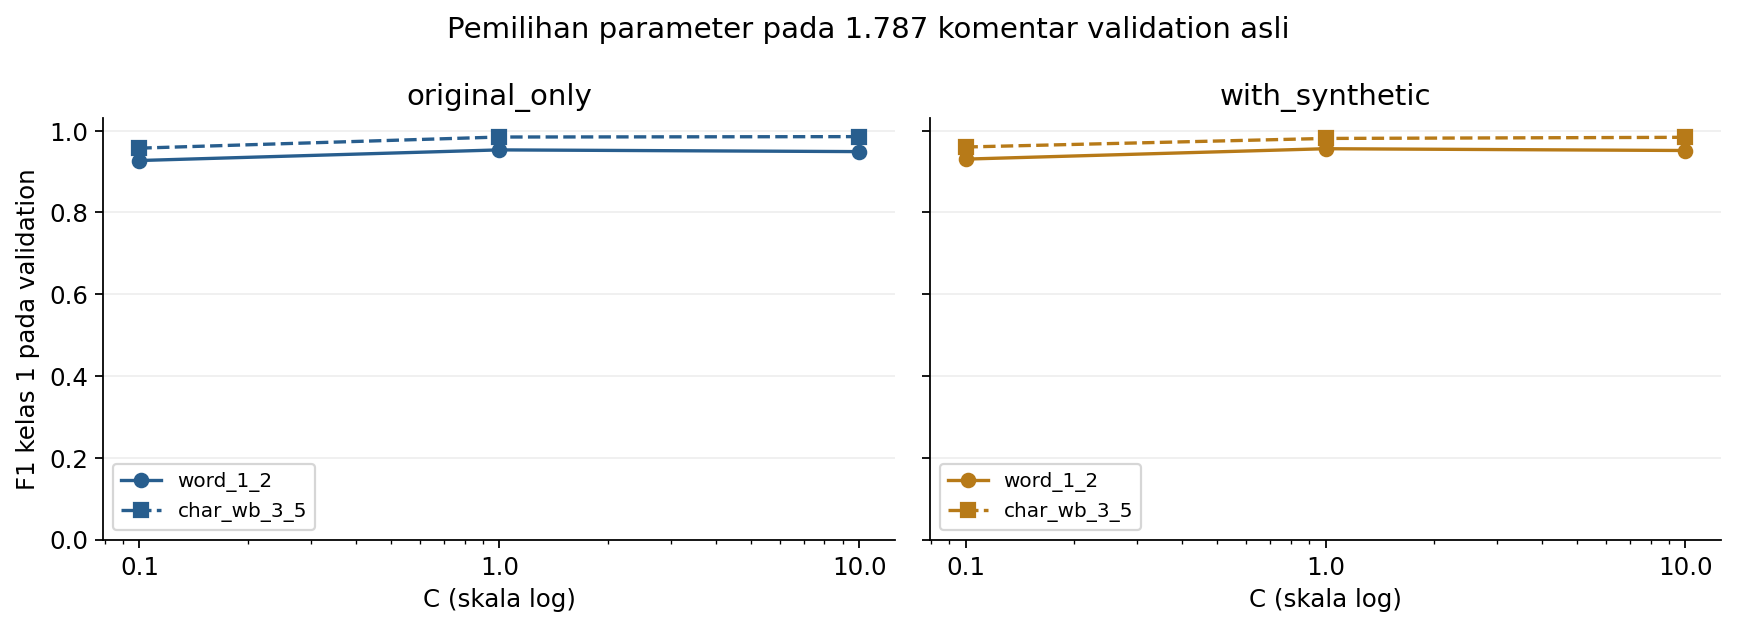

In [6]:
fig, axes = plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,arm in zip(axes,CONFIG['scenarios']):
    for feature_name,linestyle,marker in [('word_1_2','-','o'),('char_wb_3_5','--','s')]:
        subset = tuning_results.loc[tuning_results['scenario'].eq(arm) & tuning_results['features'].eq(feature_name)]
        ax.plot(subset['C'],subset['f1_1'],label=feature_name,color=COLORS[arm],linestyle=linestyle,marker=marker)
    ax.set(xscale='log',xlabel='C (skala log)',title=arm,ylim=(0,1.03))
    ax.set_xticks(CONFIG['C_values'],labels=[str(c) for c in CONFIG['C_values']])
    ax.grid(axis='y',alpha=.2)
    ax.legend(fontsize=9)
axes[0].set_ylabel('F1 kelas 1 pada validation')
fig.suptitle('Pemilihan parameter pada 1.787 komentar validation asli')
fig.tight_layout()
fig.savefig(RUN_DIR/'figures/validation_scores.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(RUN_DIR/'figures/validation_scores.png')))

## 6. Catat pilihan sebelum test

Pilih konfigurasi terbaik pada masing-masing skenario dari validation. Lalu pilih skenario berdasarkan F1 positif, dilanjutkan macro-F1 jika seri. Jika tetap seri, dahulukan data asli saja.

Pilihan disimpan sebelum evaluasi test dan tidak diubah setelah melihat hasil test.


In [7]:
feature_order = CONFIG['selection']['feature_ties']
best_per_scenario = {}
for arm in CONFIG['scenarios']:
    candidates = [record for record in tuning_records if record['scenario'] == arm]
    best_per_scenario[arm] = min(candidates,key=lambda r:(-r['f1_1'],-r['macro_f1'],feature_order.index(r['features']),r['C']))
preferred_scenario = min(CONFIG['scenarios'],key=lambda arm:(-best_per_scenario[arm]['f1_1'],-best_per_scenario[arm]['macro_f1'],CONFIG['scenarios'].index(arm)))
selection = {
    'schema_version':'1.0','run_id':RUN_ID,'locked_at':utc_now(),'config_sha256':CONFIG_SHA,
    'input_hashes':INPUT_HASHES,'selection_rule':CONFIG['selection'],
    'candidate_grid':{'features':CONFIG['features'],'C_values':CONFIG['C_values'],'scenarios':CONFIG['scenarios']},
    'best_per_scenario':best_per_scenario,'preferred_scenario':preferred_scenario,
    'validation_results_sha256':sha256_file(RUN_DIR/'validation_results.csv'),
}
write_json(RUN_DIR/'selection_locked.json',selection)
SELECTION_SHA = sha256_file(RUN_DIR/'selection_locked.json')
display(pd.DataFrame(best_per_scenario.values())[['scenario','features','C','f1_1','macro_f1']].round(5))
print('Pilihan validation:',preferred_scenario)
print('Selection record:',SELECTION_SHA)

Pilihan validation: original_only
Selection record: 9032c9ad1342a8699310567d7d51426147ca046a5c67253b2ff5fd45637fdcb1


,scenario,features,C,f1_1,macro_f1
0,original_only,char_wb_3_5,10.0,0.98531,0.98914
1,with_synthetic,char_wb_3_5,10.0,0.98363,0.98788


## 7. Refit pada train + validation

Setelah pilihan dikunci, buat pipeline baru untuk tiap skenario. Original-only memakai 7.147 komentar asli; augmented memakai 8.213 record. Vocabulary/IDF ikut dipelajari ulang dari development tersebut. Test tidak menjadi data fitting.

In [8]:
development = pd.concat([train[model_columns],validation[model_columns]],ignore_index=True)
final_models, refit_times, final_fit_rows = {}, {}, {}
for arm in CONFIG['scenarios']:
    best = best_per_scenario[arm]
    fitting_data = development if arm == 'original_only' else pd.concat([development,synthetic[model_columns]],ignore_index=True)
    require(len(fitting_data) == (7147 if arm == 'original_only' else 8213),'Jumlah refit salah.')
    pipeline = make_pipeline(best['features'],best['C'])
    elapsed, notices = fit_checked(pipeline,fitting_data)
    final_models[arm] = pipeline
    refit_times[arm], final_fit_rows[arm] = float(elapsed), len(fitting_data)
print('Refit selesai. Test belum digunakan untuk fit atau seleksi.')

Refit selesai. Test belum digunakan untuk fit atau seleksi.


## 8. Evaluasi akhir pada test asli yang sama

Test memuat 1.203 label `0` dan 584 label `1`. Baris confusion matrix adalah label rujukan dan kolomnya prediksi. False positive berarti label `0` diprediksi `1`; false negative berarti label `1` diprediksi `0`.

Skor disimpan pada skala 0–1. Margin keputusan bukan probabilitas dan tidak ditafsirkan sebagai kepastian. Kedua skenario yang telah dipilih diuji; parameter tidak diubah setelah tabel ini terlihat.

In [9]:
require(sha256_file(RUN_DIR/'selection_locked.json') == SELECTION_SHA,'Selection record berubah.')
TEST_EVALUATION_STARTED_AT = utc_now()
test_records, prediction_frames, reports, matrices = [], [], {}, {}
for arm in CONFIG['scenarios']:
    model = final_models[arm]
    start = perf_counter()
    predicted = model.predict(test['komentar_processed'])
    prediction_seconds = perf_counter()-start
    margins = model.decision_function(test['komentar_processed'])
    matrix = confusion_matrix(test['label'],predicted,labels=[0,1])
    tn,fp,fn,tp = [int(value) for value in matrix.ravel()]
    matrices[arm] = matrix.tolist()
    reports[arm] = classification_report(test['label'],predicted,labels=[0,1],output_dict=True,zero_division=0)
    test_records.append({
        'run_id':RUN_ID,'method':'SVM','classifier':'LinearSVC','scenario':arm,
        'features':best_per_scenario[arm]['features'],'C':best_per_scenario[arm]['C'],
        'fit_rows':final_fit_rows[arm],'test_rows':len(test),
        **calculate_metrics(test['label'],predicted),'tn':tn,'fp':fp,'fn':fn,'tp':tp,
        'refit_seconds':refit_times[arm],'test_predict_seconds':float(prediction_seconds),
    })
    prediction_frames.append(pd.DataFrame({
        'run_id':RUN_ID,'method':'SVM','scenario':arm,'source_row':test['source_row'],
        'split':'test','label':test['label'],'prediction':predicted,'decision_score':margins,
        'processed_text_sha256':test['komentar_processed'].map(text_sha256),
    }))
test_metrics = pd.DataFrame(test_records)
test_predictions = pd.concat(prediction_frames,ignore_index=True)
write_csv(test_metrics,RUN_DIR/'test_metrics.csv')
write_csv(test_predictions,RUN_DIR/'test_predictions.csv')
write_json(RUN_DIR/'classification_reports.json',reports)
display(test_metrics[['scenario','features','C','accuracy','precision_1','recall_1','f1_1','macro_f1']].round(5))
print('Skenario pilihan tetap dari validation:',preferred_scenario)

Skenario pilihan tetap dari validation: original_only


,scenario,features,C,accuracy,precision_1,recall_1,f1_1,macro_f1
0,original_only,char_wb_3_5,10.0,0.98769,0.99647,0.96575,0.98087,0.98590
1,with_synthetic,char_wb_3_5,10.0,0.98713,0.99471,0.96575,0.98002,0.98526


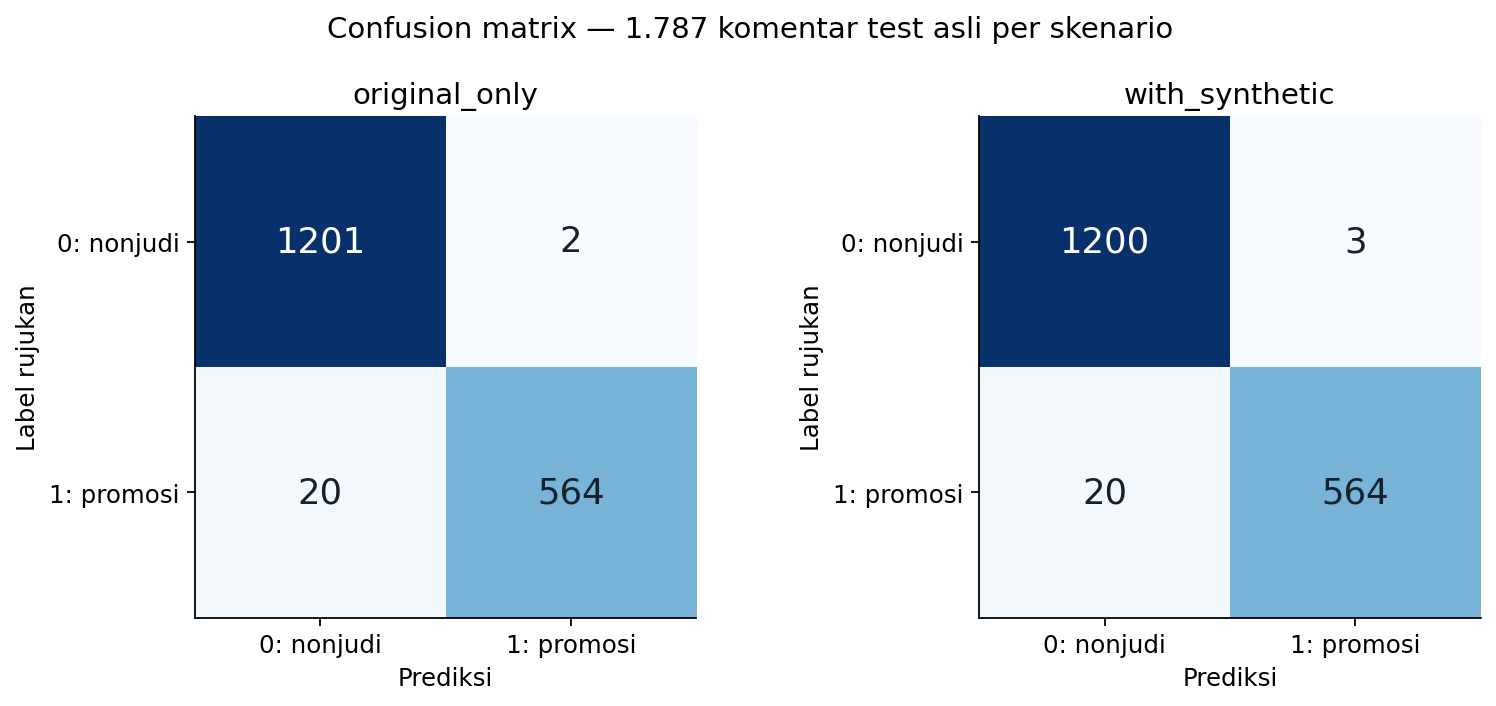

In [10]:
fig,axes = plt.subplots(1,2,figsize=(10,4.5))
maximum = max(max(row) for matrix in matrices.values() for row in matrix)
for ax,arm in zip(axes,CONFIG['scenarios']):
    matrix = np.asarray(matrices[arm])
    ax.imshow(matrix,cmap='Blues',vmin=0,vmax=maximum)
    for (i,j),count in np.ndenumerate(matrix):
        ax.text(j,i,str(count),ha='center',va='center',fontsize=16,color='white' if count > maximum/2 else '#17212B')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['0: nonjudi','1: promosi'],yticklabels=['0: nonjudi','1: promosi'],xlabel='Prediksi',ylabel='Label rujukan',title=arm)
fig.suptitle('Confusion matrix — 1.787 komentar test asli per skenario')
fig.tight_layout()
fig.savefig(RUN_DIR/'figures/confusion_matrices.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(RUN_DIR/'figures/confusion_matrices.png')))

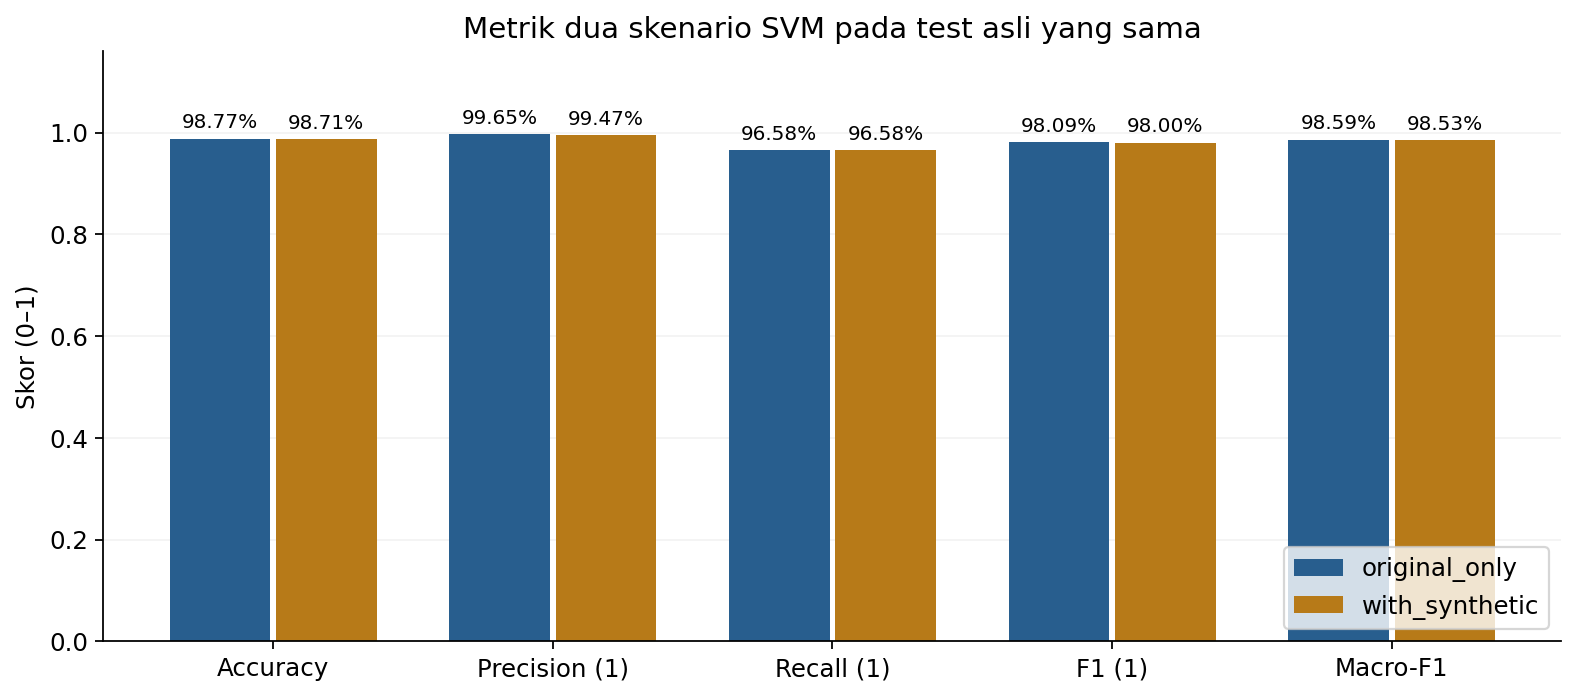

In [11]:
metric_names = ['accuracy','precision_1','recall_1','f1_1','macro_f1']
fig,ax = plt.subplots(figsize=(10,4.5))
x = np.arange(len(metric_names))
for offset,arm in [(-.19,'original_only'),(.19,'with_synthetic')]:
    row = test_metrics.loc[test_metrics['scenario'].eq(arm)].iloc[0]
    bars = ax.bar(x+offset,[row[k] for k in metric_names],width=.36,color=COLORS[arm],label=arm)
    ax.bar_label(bars,labels=[f'{row[k]*100:.2f}%' for k in metric_names],padding=3,fontsize=9)
ax.set(xticks=x,xticklabels=['Accuracy','Precision (1)','Recall (1)','F1 (1)','Macro-F1'],ylim=(0,1.16),ylabel='Skor (0–1)',title='Metrik dua skenario SVM pada test asli yang sama')
ax.legend(loc='lower right')
ax.grid(axis='y',alpha=.15)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(RUN_DIR/'figures/test_metrics.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(RUN_DIR/'figures/test_metrics.png')))

## 9. Analisis kesalahan dan fitur

Masukan adalah prediksi test yang sudah final. Kita mengekspor seluruh kesalahan kedua skenario agar contoh bisa dilacak, lalu menampilkan beberapa contoh. Label rujukan bisa mengandung masalah anotasi; contoh ini tidak dipakai untuk mengubah model atau mengoreksi skor.

Koefisien positif cenderung mendorong keputusan ke kelas `1`; negatif ke kelas `0`. Bobot adalah asosiasi dalam representasi TF-IDF yang dipelajari, bukan sebab-akibat.

In [12]:
test_errors = test_predictions.loc[test_predictions['label'].ne(test_predictions['prediction'])].merge(
    test[['source_row','komentar','komentar_processed']],on='source_row',how='left',validate='many_to_one',sort=False)
test_errors['error_type'] = np.where(test_errors['label'].eq(0),'false_positive','false_negative')
write_csv(test_errors,RUN_DIR/'test_errors.csv')
display(pd.crosstab(test_errors['scenario'],test_errors['error_type']))
for error_type in ['false_positive','false_negative']:
    print(preferred_scenario,error_type)
    display(test_errors.loc[test_errors['scenario'].eq(preferred_scenario) & test_errors['error_type'].eq(error_type),['source_row','komentar','label','prediction','decision_score']].head(5))
selected_model = final_models[preferred_scenario]
terms = selected_model.named_steps['tfidf'].get_feature_names_out()
coefficients = selected_model.named_steps['svm'].coef_[0]
require(len(terms) == len(coefficients),'Nama fitur dan koefisien tidak sejajar.')
weights = pd.DataFrame({'feature':terms,'coefficient':coefficients})
write_csv(weights,RUN_DIR/'selected_model_feature_weights.csv')

original_only false_positive
original_only false_negative


error_type,false_negative,false_positive
scenario,,
original_only,20,2
with_synthetic,20,3


,source_row,komentar,label,prediction,decision_score
1,6726,Belik cilok depan alfa 5k 🗿👍🏿,0,1,0.630470
12,1967,"sepeda udah ga maen , golf",0,1,0.476051


,source_row,komentar,label,prediction,decision_score
0,5492,"Tidak pernah merasa bosan sedikit pun bermain 𝐷𝑂R𝐴77, karena selalu ada inovasi dan kejutan!",1,0,-0.172383
2,1838,wadidaw kren bgt yak depo 50 doan jd 2jt wwk💫💫,1,0,-0.695816
3,6611,akari awetnya terbaik,1,0,-0.590455
4,5793,buseettt bener,1,0,-0.986715
5,1455,wajib coba sih coba mantep banget,1,0,-0.140819


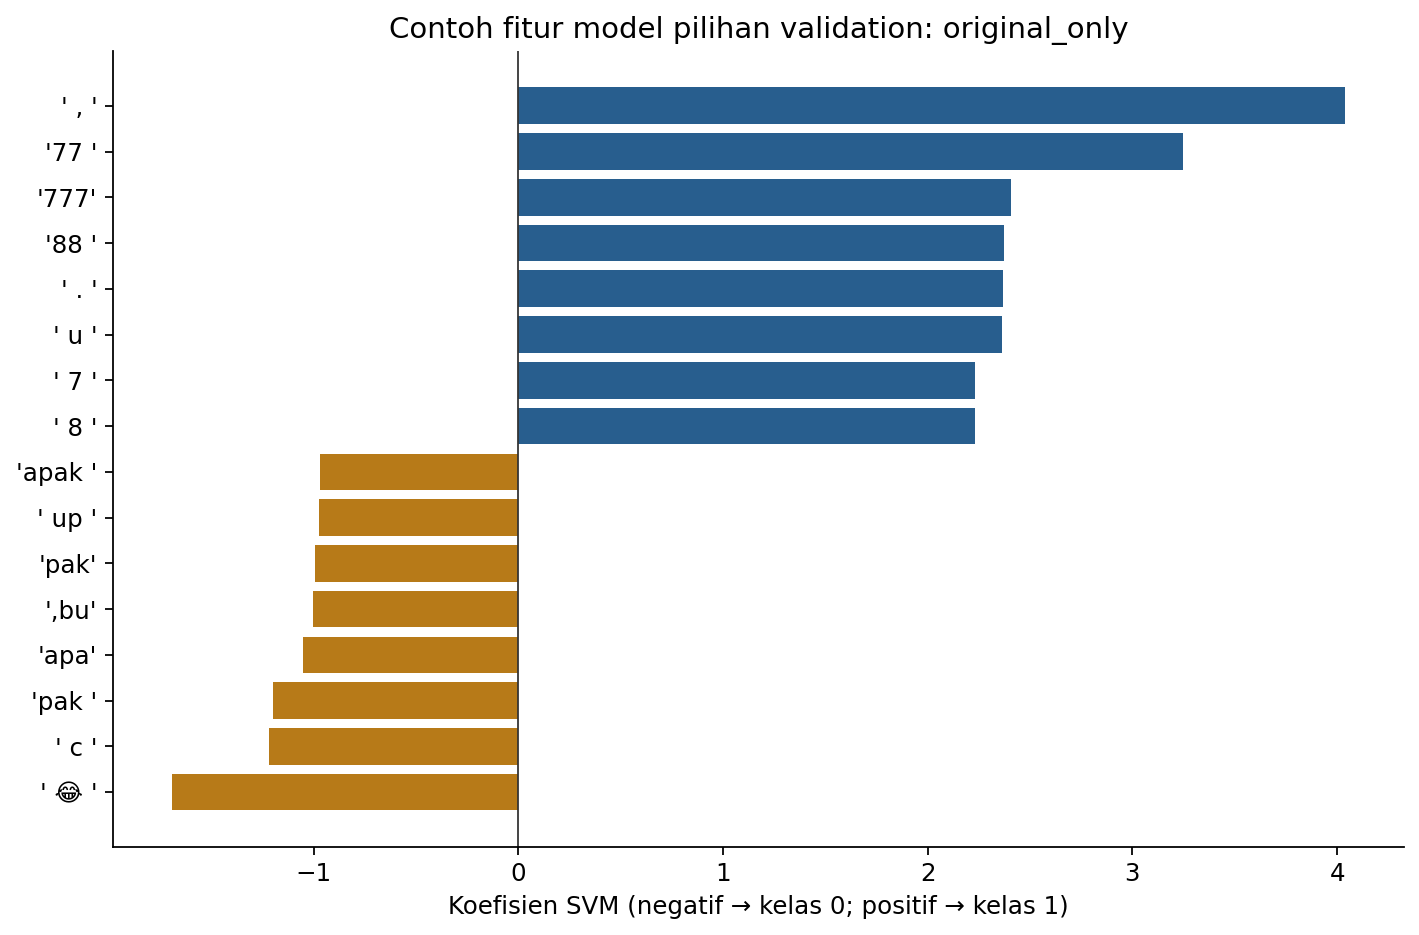

In [13]:
visible = pd.concat([weights.nsmallest(8,'coefficient'),weights.nlargest(8,'coefficient')]).sort_values('coefficient')
fig,ax = plt.subplots(figsize=(9,6))
ax.barh(np.arange(len(visible)),visible['coefficient'],color=['#B77A18' if value < 0 else '#285E8E' for value in visible['coefficient']])
ax.set_yticks(np.arange(len(visible)),labels=[repr(term) for term in visible['feature']])
ax.axvline(0,color='#333333',linewidth=.8)
ax.set(xlabel='Koefisien SVM (negatif → kelas 0; positif → kelas 1)',title=f'Contoh fitur model pilihan validation: {preferred_scenario}')
fig.tight_layout()
fig.savefig(RUN_DIR/'figures/selected_model_features.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(RUN_DIR/'figures/selected_model_features.png')))

## 10. Simpan model dan demonstrasikan pemakaian

Pipeline menerima teks yang sudah dibersihkan. `predict.py` menerima komentar mentah, menjalankan fungsi cleaning yang sama, lalu menerapkan pipeline tersimpan. Contoh buatan di bawah hanya demonstrasi dan tidak masuk metrik.

Kedua pipeline disimpan tanpa fitting pada test. Hanya muat file joblib dari sumber yang dipercaya.

In [14]:
for arm,model in final_models.items():
    path = RUN_DIR/'models'/f'svm_{arm}.joblib'
    temporary = path.with_name(path.name+'.tmp')
    joblib.dump(model,temporary,compress=3)
    temporary.replace(path)
    restored = joblib.load(path)
    require(np.array_equal(restored.predict(test['komentar_processed']),model.predict(test['komentar_processed'])),'Prediksi reload berbeda.')
from predict import predict_comments
demo_comments = ['Videonya membantu, terima kasih bang','depo receh di SITUSDEMO88, wd lancar','Tolong hapus spam judi di komentar ini']
display(pd.DataFrame(predict_comments(RUN_DIR/'models'/f'svm_{preferred_scenario}.joblib',demo_comments)))

,komentar,komentar_processed,prediction,decision_score
0,"Videonya membantu, terima kasih bang","videonya membantu, terima kasih bang",0,-0.919419
1,"depo receh di SITUSDEMO88, wd lancar","depo receh di situsdemo88, wd lancar",1,1.595100
2,Tolong hapus spam judi di komentar ini,tolong hapus spam judi di komentar ini,0,-0.960849


## 11. Periksa hasil

Pemeriksa membaca prediksi yang diekspor, mencocokkannya dengan data test, dan menghitung ulang metrik dari TP/TN/FP/FN. Kedua model juga dimuat ulang untuk memeriksa prediksi, margin, dan bobot fitur.

Catatan teknis disimpan otomatis untuk penulis paper. Pemeriksaan ini memastikan hasil konsisten; kebenaran anotasi dan kemampuan pada data baru masih perlu penelitian lain.


In [15]:
require(verify_input_hashes(ROOT)[1] == INPUT_HASHES,'Input berubah selama run.')
require(code_fingerprints(ROOT) == CODE_HASHES,'Kode/config berubah selama run.')
summary = {
    'schema_version':'1.0','run_id':RUN_ID,'status':'computed','method':'SVM','classifier':'LinearSVC',
    'started_at':STARTED_AT,'computed_at':utc_now(),'test_evaluation_started_at':TEST_EVALUATION_STARTED_AT,
    'execution_mode':EXECUTION_MODE,'config_sha256':CONFIG_SHA,'config':CONFIG,
    'selection_sha256':SELECTION_SHA,'preferred_scenario':preferred_scenario,'input_hashes':INPUT_HASHES,
    'upstream_repository':shared['contract']['repository'],'upstream_commit':shared['contract']['commit'],
    'code_fingerprints':CODE_HASHES,'git':git_identity(ROOT),
    'environment':{'python':platform.python_version(),'versions':VERSIONS,'platform':platform.platform(),'cpu':platform.processor() or platform.machine(),'logical_cpus':os.cpu_count()},
    'upstream_environment':CONFIG['upstream_environment'],
    'environment_deviation':'Eksekusi offline memakai scikit-learn 1.4.2 dan versi library sesuai environment. Kontrak data/fitur/split/seleksi tetap sama; lihat docs/LINGKUNGAN.md.',
    'label_mapping':{'0':'nonjudi (pemetaan kerja)','1':'promosi judi (pemetaan kerja)'},
    'split_counts':shared['contract']['split_counts'],'class_counts':shared['contract']['class_counts'],
    'synthetic_rows':len(synthetic),'final_fit_rows':final_fit_rows,'test_metrics':{r['scenario']:r for r in test_records},
    'confusion_matrices':matrices,'validation_candidates':len(tuning_records),
    'timing':{'candidate_fit':'TF-IDF + LinearSVC fit; excludes CSV load and validation prediction','refit':'fresh TF-IDF + LinearSVC on development','test_predict':'Pipeline.predict only; excludes separate decision_function call','total_tuning_fit_seconds':float(tuning_results['fit_seconds'].sum())},
    'final_model_details':{arm:{'feature_count':len(model.named_steps['tfidf'].vocabulary_),'n_iter':int(np.max(model.named_steps['svm'].n_iter_)),'classes':[int(x) for x in model.classes_],'parameters':model.named_steps['svm'].get_params()} for arm,model in final_models.items()},
    'model_input':'komentar_processed; gunakan preprocessing.clean_comment untuk komentar mentah',
    'limitations':['Arti label dan proses anotasi sumber belum terkonfirmasi.','Random unique-text split bukan holdout video/kampanye.','Template mirip dapat melintasi split.','Synthetic bukan observasi YouTube independen.','Versi lingkungan berbeda dari upstream dan waktu fit bergantung hardware.'],
}
write_json(RUN_DIR/'experiment_summary.json',summary)
from scripts.verify_run import verify_run
verification = verify_run(ROOT,RUN_DIR,check_models=True,save=True)
summary['status'] = 'computationally_verified'
summary['verification_status'] = verification['status']
summary['jupyter_kernel_verified'] = verification['jupyter_kernel_verified']
write_json(RUN_DIR/'experiment_summary.json',summary)
write_artifact_manifest(RUN_DIR)
write_json(ROOT/'outputs/latest_run.json',{'run_id':RUN_ID,'path':RUN_DIR.relative_to(ROOT).as_posix(),'execution_mode':EXECUTION_MODE})
print('Verifikasi:',verification['status'])
print('Pemeriksaan kernel Jupyter:',verification['jupyter_kernel_verified'])
print('Run:',RUN_DIR.relative_to(ROOT))

Verifikasi: passed
Pemeriksaan kernel Jupyter: False
Run: outputs\runs\20261021T144408Z_faf70e90


## 12. Baca ringkasan dan serahkan hasil

Sel berikut merangkum kedua skenario SVM. Skenario pilihan tetap mengikuti validation. Selisih kecil pada satu split belum membuktikan perbedaan yang signifikan.

Untuk membuat satu ZIP lengkap bagi penulis paper, jalankan `python scripts/package_run.py` dari terminal di folder repo. Format tabel dan prediksi dijelaskan dalam [panduan metode](docs/METODE_SVM.md).


In [16]:
for record in test_records:
    print(f"{record['scenario']}: accuracy={record['accuracy']:.4%}, precision(1)={record['precision_1']:.4%}, recall(1)={record['recall_1']:.4%}, F1(1)={record['f1_1']:.4%}, macro-F1={record['macro_f1']:.4%}")
delta_f1 = test_records[1]['f1_1']-test_records[0]['f1_1']
print(f'Perubahan F1 positif dengan synthetic: {delta_f1*100:+.3f} poin persentase.')
print('Ini deskripsi hasil dua skenario SVM, bukan perbandingan dengan model anggota lain.')
print('Mode run:',EXECUTION_MODE)

original_only: accuracy=98.7689%, precision(1)=99.6466%, recall(1)=96.5753%, F1(1)=98.0870%, macro-F1=98.5897%
with_synthetic: accuracy=98.7129%, precision(1)=99.4709%, recall(1)=96.5753%, F1(1)=98.0017%, macro-F1=98.5263%
Perubahan F1 positif dengan synthetic: -0.085 poin persentase.
Ini deskripsi hasil dua skenario SVM, bukan perbandingan dengan model anggota lain.
Mode run: sequential_ipython
